In [1]:
# === Cell 1: Setup ===
!pip install -q transformers datasets accelerate evaluate

# === Cell 2: Mount Drive ===
from google.colab import drive
drive.mount('/content/drive')

# === Cell 3: Imports + GPU check ===
import os, time
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from datasets import Dataset, DatasetDict
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
from transformers import (
    AutoTokenizer, AutoModelForSequenceClassification,
    TrainingArguments, Trainer, DataCollatorWithPadding,
    EarlyStoppingCallback,
)

print(f"CUDA available: {torch.cuda.is_available()}")
print(f"Device:         {torch.cuda.get_device_name(0)}")
print(f"GPU memory:     {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 1.9 MB/s eta 0:00:00
Mounted at /content/drive
CUDA available: True
Device:         Tesla T4
GPU memory:     14.6 GB


In [2]:
# === Cell 4b: Reload full DataFrames with marked_* columns + rebuild label dicts ===
DATA_DIR = "/content/drive/MyDrive/thesis_stage2"
MODEL_NAME = "roberta-base"

# Prepare all dfs
df_train = pd.read_csv(f"{DATA_DIR}/patternreframe_train.csv")
df_val   = pd.read_csv(f"{DATA_DIR}/patternreframe_val.csv")
df_test  = pd.read_csv(f"{DATA_DIR}/patternreframe_test.csv")

# Drop NaN rows in required columns
marked_cols = [c for c in df_train.columns if c.startswith("marked_")]
required_cols = ["thought", "pattern"] + marked_cols
df_train = df_train.dropna(subset=required_cols)
df_val   = df_val.dropna(subset=required_cols)
df_test  = df_test.dropna(subset=["thought", "pattern"])

# Rebuild label dictionaries (sorted alphabetically for determinism)
classes  = sorted(df_train["pattern"].unique())
label2id = {label: idx for idx, label in enumerate(classes)}
id2label = {idx: label for label, idx in label2id.items()}

print(f"Train: {len(df_train)}, Val: {len(df_val)}, Test: {len(df_test)}")
print(f"marked_* columns present: {len(marked_cols)}")
print(f"\nLabel mapping:")
for idx, label in id2label.items():
    print(f"  {idx:>2}  {label}")

Train: 1920, Val: 961, Test: 6807
marked_* columns present: 12

Label mapping:
   0  Black-and-white or polarized thinking / All or nothing thinking
   1  Catastrophizing
   2  Discounting the positive
   3  Jumping to conclusions: Fortune-telling
   4  Jumping to conclusions: mind reading
   5  Labeling and mislabeling
   6  Mental filtering
   7  Overgeneralization
   8  Personalization
   9  Should statements


In [3]:
# === Cell 5: Tokenise ===
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def make_dataset(df):
    return Dataset.from_pandas(
        df[["thought", "pattern"]]
            .rename(columns={"thought": "text"})
            .assign(label=lambda d: d["pattern"].map(label2id))
            [["text", "label"]],
        preserve_index=False,
    )

raw_datasets = DatasetDict({
    "train":      make_dataset(df_train),
    "validation": make_dataset(df_val),
    "test":       make_dataset(df_test),
})

# Thoughts are short (~25 tokens median), so 256 is more than enough
# and keeps memory footprint low. None will be truncated.
def tokenize_function(batch):
    return tokenizer(batch["text"], truncation=True, max_length=256)

tokenized_datasets = raw_datasets.map(
    tokenize_function, batched=True, remove_columns=["text"]
)

# Quick verification: confirm no truncation actually happened (input_ids - token ids from tokenizer)
sample_lengths = [len(x["input_ids"]) for x in tokenized_datasets["train"]]
print(f"Token length stats (training set):")
print(f"  Mean: {np.mean(sample_lengths):.1f}, Max: {max(sample_lengths)}, Min: {min(sample_lengths)}")
print(f"  Records hitting 256-token cap: {sum(1 for l in sample_lengths if l == 256)}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Map:   0%|          | 0/1920 [00:00<?, ? examples/s]

Map:   0%|          | 0/961 [00:00<?, ? examples/s]

Map:   0%|          | 0/6807 [00:00<?, ? examples/s]

Token length stats (training set):
  Mean: 23.2, Max: 63, Min: 9
  Records hitting 256-token cap: 0


In [4]:
# === Cell 6 v2: Soft-label training (PatternReframe, 10 classes) ===
# 1. Mapping: marked_* column → label name (exactly as in label2id)
MARKED_COL_TO_PATTERN = {
    "marked_black_and_white":      "Black-and-white or polarized thinking / All or nothing thinking",
    "marked_catastrophizing":      "Catastrophizing",
    "marked_discounting_positive": "Discounting the positive",
    "marked_fortune_telling":      "Jumping to conclusions: Fortune-telling",
    "marked_labeling":             "Labeling and mislabeling",
    "marked_mental_filtering":     "Mental filtering",
    "marked_mind_reading":         "Jumping to conclusions: mind reading",
    "marked_overgeneralization":   "Overgeneralization",
    "marked_personalization":      "Personalization",
    "marked_should_statements":    "Should statements",
}
# Note: marked_emotional_reasoning is excluded — it is always 0 in train.
# Note: marked_none is excluded — our 10-class model has no None output, so
#       any probability mass on it would have nowhere to go.

assert len(MARKED_COL_TO_PATTERN) == len(label2id), \
    f"Mapping has {len(MARKED_COL_TO_PATTERN)} entries but label2id has {len(label2id)}"

# 2. Build soft-label arrays
def build_soft_labels(df, num_labels):
    """For each row, return a (num_labels,) vector summing to 1.0 from the marked_* votes."""
    soft = np.zeros((len(df), num_labels), dtype=np.float32)

    for col, pattern in MARKED_COL_TO_PATTERN.items():
        if col not in df.columns:
            raise ValueError(f"Column {col!r} not found in CSV.")
        if pattern not in label2id:
            raise ValueError(f"Pattern {pattern!r} not in label2id.")
        idx = label2id[pattern]
        soft[:, idx] = df[col].values.astype(np.float32)

    # Some rows may have zero votes on the 10 distortions (all votes went to None or Emotional Reasoning).
    # Fall back to one-hot on the hard label for those rows.
    row_sums = soft.sum(axis=1)
    no_votes_mask = row_sums == 0
    n_fallback = int(no_votes_mask.sum())
    if n_fallback > 0:
        print(f"  {n_fallback} rows had no votes on the 10 distortion patterns; "
              f"using one-hot fallback on the hard label.")
        for i in np.where(no_votes_mask)[0]:
            hard_label = df.iloc[i]["pattern"]
            soft[i, label2id[hard_label]] = 1.0
            row_sums[i] = 1.0

    # Normalise per row to sum to 1.0
    soft = soft / row_sums[:, None]
    return soft

print("Building soft-label arrays:")
print("  Train:")
train_soft = build_soft_labels(df_train, num_labels=len(label2id))
print("  Val:")
val_soft   = build_soft_labels(df_val,   num_labels=len(label2id))

print(f"\nShapes: train {train_soft.shape}, val {val_soft.shape}")
print(f"Row sums (sanity, should be 1.0): {train_soft.sum(axis=1)[:5]}")
print(f"\nExample (row 0):")
print(f"  Hard label: {df_train.iloc[0]['pattern']}")
for label_idx, label_name in id2label.items():
    if train_soft[0, label_idx] > 0:
        print(f"    {train_soft[0, label_idx]:.3f}  {label_name}")

# 3. Attach soft labels to the tokenised datasets
def add_soft_labels(ds, soft_array):
    return ds.add_column("soft_labels", soft_array.tolist())

tokenized_datasets["train"]      = add_soft_labels(tokenized_datasets["train"], train_soft)
tokenized_datasets["validation"] = add_soft_labels(tokenized_datasets["validation"], val_soft)
# Test set keeps only the hard label — evaluation is against ground truth labels

# 4. Custom Trainer with soft-label cross-entropy loss
class SoftLabelTrainer(Trainer):
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        # Pop soft labels if they are present (training / validation).
        # On the test set they are absent, so fall back to hard-label CE.
        soft_labels = inputs.pop("soft_labels") if "soft_labels" in inputs else None
        labels = inputs.pop("labels") if "labels" in inputs else None

        outputs = model(**inputs)
        logits = outputs.logits  # (batch, num_labels)

        if soft_labels is not None:
            # Soft-label cross-entropy: -sum(target * log_softmax(logits))
            log_probs = F.log_softmax(logits, dim=-1)
            loss = -(soft_labels * log_probs).sum(dim=-1).mean()
        elif labels is not None:
            # Hard-label fallback (used during predict() on the test set)
            loss = F.cross_entropy(logits, labels)
        else:
            # No labels at all — return zero loss, predict() only needs logits
            loss = torch.tensor(0.0, device=logits.device)

        return (loss, outputs) if return_outputs else loss

# 5. Custom collator that adds the soft_labels column to the batch
# (collator stacks list of examples in a single batch tensor which goes to trainer)
class SoftLabelCollator:
    def __init__(self, tokenizer):
        self.base = DataCollatorWithPadding(tokenizer=tokenizer)
    def __call__(self, features):
        # Pop soft_labels only if present (training/validation has them; test does not)
        if "soft_labels" in features[0]:
            soft_labels = torch.tensor(
                [f.pop("soft_labels") for f in features],
                dtype=torch.float32,
            )
        else:
            soft_labels = None
        batch = self.base(features)
        if soft_labels is not None:
            batch["soft_labels"] = soft_labels
        return batch

data_collator = SoftLabelCollator(tokenizer)

# 6. Metrics function — unchanged. Evaluation uses hard labels.
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    return {
        "accuracy":    accuracy_score(labels, predictions),
        "f1_weighted": f1_score(labels, predictions, average="weighted"),
        "f1_macro":    f1_score(labels, predictions, average="macro"),
    }

# 7. Fresh model
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(label2id), id2label=id2label, label2id=label2id,
)

# 8. Training arguments — same as previous run, only output_dir and remove_unused_columns differ
training_args = TrainingArguments(
    output_dir=f"{DATA_DIR}/roberta_patternreframe_softlabels_seed42",
    learning_rate=1e-5,
    weight_decay=0.01,
    max_grad_norm=1.0,
    num_train_epochs=10,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    warmup_steps=100,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="f1_weighted",
    greater_is_better=True,
    logging_strategy="epoch",
    report_to="none",
    seed=42,
    fp16=False,
    bf16=False,
    remove_unused_columns=False,         # keep soft_labels in the dataset
)

# 9. SoftLabelTrainer instead of Trainer
trainer = SoftLabelTrainer(
    model=model, args=training_args,
    train_dataset=tokenized_datasets["train"],
    eval_dataset=tokenized_datasets["validation"],
    processing_class=tokenizer,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=3)],
)

Building soft-label arrays:
  Train:
  Val:

Shapes: train (1920, 10), val (961, 10)
Row sums (sanity, should be 1.0): [1. 1. 1. 1. 1.]

Example (row 0):
  Hard label: Catastrophizing
    0.444  Catastrophizing
    0.111  Discounting the positive
    0.444  Jumping to conclusions: Fortune-telling


model.safetensors:   0%|          | 0.00/499M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                             | Status     | 
--------------------------------+------------+-
lm_head.dense.bias              | UNEXPECTED | 
roberta.embeddings.position_ids | UNEXPECTED | 
lm_head.bias                    | UNEXPECTED | 
lm_head.layer_norm.bias         | UNEXPECTED | 
lm_head.layer_norm.weight       | UNEXPECTED | 
lm_head.dense.weight            | UNEXPECTED | 
classifier.out_proj.bias        | MISSING    | 
classifier.dense.weight         | MISSING    | 
classifier.dense.bias           | MISSING    | 
classifier.out_proj.weight      | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [5]:
# === Cell 7: Train ===
start = time.time()
train_result = trainer.train()
print(f"\nTraining finished in {(time.time() - start)/60:.1f} minutes")

Epoch,Training Loss,Validation Loss,Accuracy,F1 Weighted,F1 Macro
1,2.257726,1.939561,0.276795,0.183924,0.183682
2,1.667269,1.499267,0.457856,0.406433,0.410825
3,1.501719,1.486721,0.493236,0.450587,0.454862
4,1.455814,1.484982,0.488033,0.450716,0.455427
5,1.424650,1.480870,0.528616,0.508311,0.514087
6,1.403803,1.481642,0.499480,0.474857,0.479924
7,1.383959,1.481674,0.537981,0.528192,0.534064
8,1.373339,1.480323,0.528616,0.510781,0.516583
9,1.363354,1.482532,0.530697,0.514292,0.519567
10,1.353205,1.480517,0.528616,0.515124,0.520664


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['roberta.embeddings.LayerNorm.weight', 'roberta.embeddings.LayerNorm.bias', 'roberta.encoder.layer.0.attention.output.LayerNorm.weight', 'roberta.encoder.layer.0.attention.output.LayerNorm.bias', 'roberta.encoder.layer.0.output.LayerNorm.weight', 'roberta.encoder.layer.0.output.LayerNorm.bias', 'roberta.encoder.layer.1.attention.output.LayerNorm.weight', 'roberta.encoder.layer.1.attention.output.LayerNorm.bias', 'roberta.encoder.layer.1.output.LayerNorm.weight', 'roberta.encoder.layer.1.output.LayerNorm.bias', 'roberta.encoder.layer.2.attention.output.LayerNorm.weight', 'roberta.encoder.layer.2.attention.output.LayerNorm.bias', 'roberta.encoder.layer.2.output.LayerNorm.weight', 'roberta.encoder.layer.2.output.LayerNorm.bias', 'roberta.encoder.layer.3.attention.output.LayerNorm.weight', 'roberta.encoder.layer.3.attention.output.LayerNorm.bias', 'roberta.encoder.layer.3.output.LayerNorm.weight', 'roberta.encoder.layer.3.output.Laye


Training finished in 5.4 minutes


In [6]:
# === Cell 8: Save final model ===
FINAL_PATH = f"{DATA_DIR}/roberta_patternreframe_softlabels_final"
trainer.save_model(FINAL_PATH)
tokenizer.save_pretrained(FINAL_PATH)
print(f"Model saved to {FINAL_PATH}")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Model saved to /content/drive/MyDrive/thesis_stage2/roberta_patternreframe_softlabels_final


In [7]:
# === Cell 9: Test set evaluation ===
# Cell 9 should run unchanged
test_predictions = trainer.predict(tokenized_datasets["test"])
y_pred = np.argmax(test_predictions.predictions, axis=-1)
y_true = test_predictions.label_ids

print("=== Test set metrics ===")
for k, v in test_predictions.metrics.items():
    print(f"  {k}: {v:.4f}" if isinstance(v, float) else f"  {k}: {v}")

=== Test set metrics ===
  test_loss: 1.3391
  test_accuracy: 0.5628
  test_f1_weighted: 0.5556
  test_f1_macro: 0.5566
  test_runtime: 17.5658
  test_samples_per_second: 387.5140
  test_steps_per_second: 12.1260


Saved predictions to /content/drive/MyDrive/thesis_stage2/roberta_patternreframe_softlabels_test_predictions.csv


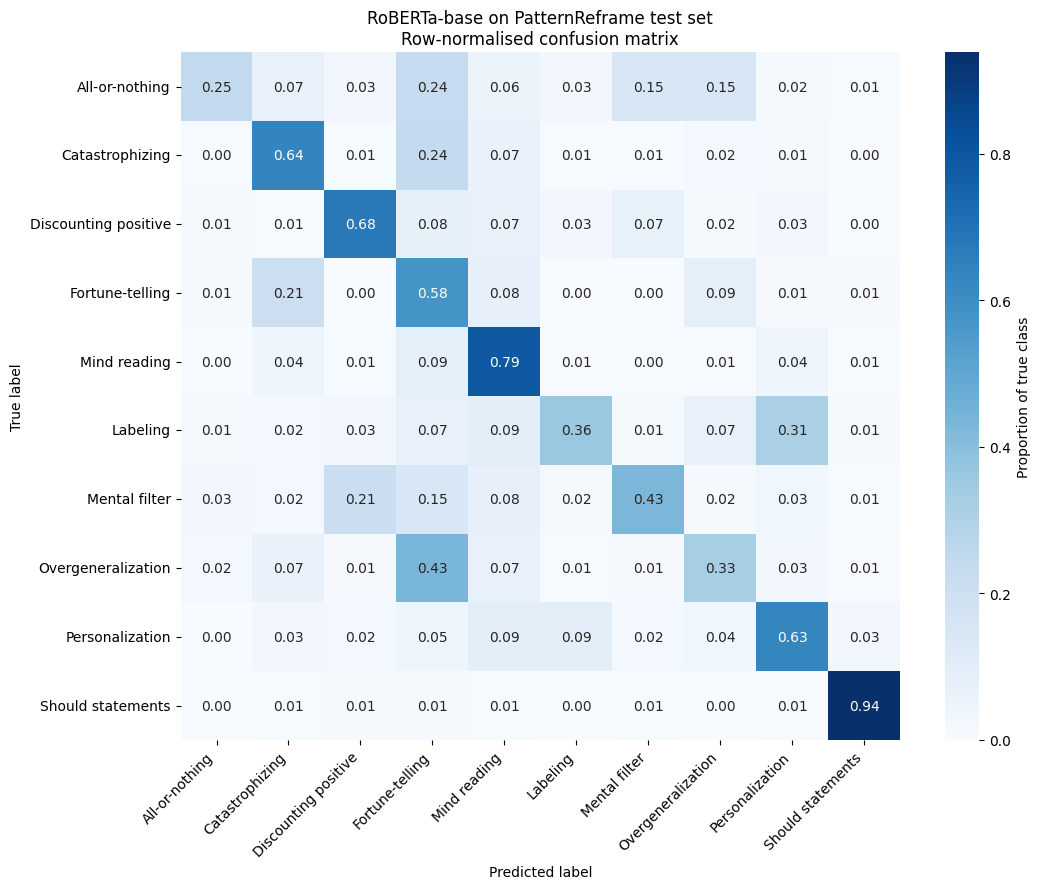

Saved to /content/drive/MyDrive/thesis_stage2/confusion_matrix_patternreframe_softlabels.png


In [8]:
# === Cell 10: Save predictions and confusion matrix ===
import matplotlib.pyplot as plt
import seaborn as sns

# Save full predictions with class probabilities
predictions_df = pd.DataFrame({
    "y_true":     y_true,
    "y_pred":     y_pred,
    "true_label": [id2label[i] for i in y_true],
    "pred_label": [id2label[i] for i in y_pred],
})
probs = torch.nn.functional.softmax(
    torch.tensor(test_predictions.predictions), dim=-1
).numpy()
for idx in range(len(id2label)):
    predictions_df[f"prob_{idx}"] = probs[:, idx]
predictions_df.to_csv(f"{DATA_DIR}/roberta_patternreframe_softlabels_test_predictions.csv", index=False)
print(f"Saved predictions to {DATA_DIR}/roberta_patternreframe_softlabels_test_predictions.csv")

# Short labels for the confusion matrix axes (full names are too long)
short_labels = {
    "Black-and-white or polarized thinking / All or nothing thinking": "All-or-nothing",
    "Catastrophizing":                                                  "Catastrophizing",
    "Discounting the positive":                                         "Discounting positive",
    "Jumping to conclusions: Fortune-telling":                          "Fortune-telling",
    "Jumping to conclusions: mind reading":                             "Mind reading",
    "Labeling and mislabeling":                                         "Labeling",
    "Mental filtering":                                                 "Mental filter",
    "Overgeneralization":                                               "Overgeneralization",
    "Personalization":                                                  "Personalization",
    "Should statements":                                                "Should statements",
}
labels = [id2label[i] for i in range(len(id2label))]
short_axis = [short_labels.get(l, l) for l in labels]

# Row-normalised confusion matrix
cm = confusion_matrix(y_true, y_pred)
cm_normalized = cm.astype(float) / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    cm_normalized,
    annot=True, fmt=".2f", cmap="Blues",
    xticklabels=short_axis, yticklabels=short_axis,
    cbar_kws={"label": "Proportion of true class"},
    ax=ax,
)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title("RoBERTa-base on PatternReframe test set\nRow-normalised confusion matrix")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(f"{DATA_DIR}/confusion_matrix_patternreframe_softlabels.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved to {DATA_DIR}/confusion_matrix_patternreframe_softlabels.png")

In [9]:
from scipy.stats import entropy
ent = np.array([entropy(row) for row in train_soft])
print(f"Mean entropy: {ent.mean():.3f}  (max for 10 classes: {np.log(10):.3f})")
print(f"Fraction of rows with entropy > 0.5: {(ent > 0.5).mean():.2%}")
print(f"Fraction of rows that are one-hot:   {(ent == 0).mean():.2%}")

Mean entropy: 1.009  (max for 10 classes: 2.303)
Fraction of rows with entropy > 0.5: 86.20%
Fraction of rows that are one-hot:   8.49%


In [ ]:
# === Inspect Cell: verify marked_* columns ===
df = pd.read_csv("/content/drive/MyDrive/thesis_stage2/patternreframe_train.csv")
marked_cols = sorted([c for c in df.columns if c.startswith("marked_")])
print(f"Number of marked_ columns: {len(marked_cols)}")
print("\nColumn names and value ranges:")
for c in marked_cols:
    print(f"  {c:<40s}  min={int(df[c].min())}  max={int(df[c].max())}  mean={df[c].mean():.2f}")

print("\nSample row 0:")
print("  pattern (hard label):", df.iloc[0]["pattern"])
for c in marked_cols:
    print(f"  {c}: {int(df.iloc[0][c])}")

print(f"\nSum of marked_* per row (first 5):")
print(df[marked_cols].sum(axis=1).head())

Number of marked_ columns: 12

Column names and value ranges:
  marked_black_and_white                    min=0  max=5  mean=0.43
  marked_catastrophizing                    min=0  max=5  mean=0.95
  marked_discounting_positive               min=0  max=5  mean=0.75
  marked_emotional_reasoning                min=0  max=0  mean=0.00
  marked_fortune_telling                    min=0  max=5  mean=1.14
  marked_labeling                           min=0  max=5  mean=0.51
  marked_mental_filtering                   min=0  max=5  mean=0.66
  marked_mind_reading                       min=0  max=5  mean=0.74
  marked_none                               min=0  max=2  mean=0.13
  marked_overgeneralization                 min=0  max=5  mean=0.86
  marked_personalization                    min=0  max=5  mean=0.72
  marked_should_statements                  min=0  max=5  mean=0.43

Sample row 0:
  pattern (hard label): Catastrophizing
  marked_black_and_white: 0
  marked_catastrophizing: 4
  marked_di